In [1]:
import xarray as xr
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

In [2]:
def get_run_names(str_list):
    run_names = []
    for i,string in enumerate(str_list):
        run_names.append(string.split("_")[0]+'_'+string.split("_")[1])
    return run_names

In [3]:
def normalize(DA):
    start_date = '1950-06-30T12:00:00.000000000'
    end_date = '2000-06-30T12:00:00.000000000'
    mean = DA.loc[start_date:end_date].mean('time')
    std_dev = DA.loc[start_date:end_date].std('time')
    normalized_DA = (DA-mean)/std_dev
    return normalized_DA

In [4]:
def rollmean(DA,n_months=3*10):
    running_mean = DA.rolling(time=n_months,center='True').mean('time')#.fillna(0)
    return running_mean

In [5]:
def select_reference_period(arr):
    start_date = '1931-06-30T12:00:00.000000000'
    end_date = '2014-07-31T12:00:00.000000000'
    return arr.loc[start_date:end_date]

def compute_freq_distribution(freq_list,n_months=3*10):
    freqs = []
    for elmnt in tqdm(freq_list):
        freqs.append(np.amax(rollmean(elmnt)))
    freqs_np_arr = np.array(freqs)
    return freqs_np_arr

def compute_ERA5_max_freq(freq,n_months=3*10):
    freq =  rollmean(freq).fillna(0)
    freq_np_array = np.array(freq)
    return freq,np.amax(freq_np_array),np.argmax(freq_np_array)

In [7]:
'''
Importing the datasets GHA
'''
import os
# Path to the dataset directory
GHA_path = "/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/historical/"

%cd /emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/historical/

# List all files, excluding those with 'unfilt' in the name
GHA_file_list_all = [
    f for f in os.listdir(GHA_path) 
    if os.path.isfile(os.path.join(GHA_path, f)) and 'GHA' in f and 'all' in f# and 'CanESM' in f 
]

GHA_file_list_all = sorted(GHA_file_list_all)

# List all files, excluding those with 'unfilt' in the name
GHA_file_list_retrograding = [
    f for f in os.listdir(GHA_path) 
    if os.path.isfile(os.path.join(GHA_path, f)) and 'GHA' in f and 'retrograding' in f# and 'CanESM' in f 
]

GHA_file_list_retrograding = sorted(GHA_file_list_retrograding)

# List all files, excluding those with 'unfilt' in the name
GHA_file_list_upstream = [
    f for f in os.listdir(GHA_path) 
    if os.path.isfile(os.path.join(GHA_path, f)) and 'GHA' in f and 'upstream' in f# and 'CanESM' in f 
]

GHA_file_list_upstream = sorted(GHA_file_list_upstream)

#import data
GHA_DAs_all = []
for name in GHA_file_list_all:
    GHA_DAs_all.append(xr.open_dataset(name)['GHA monthly blocking frequency'])
#import data
GHA_DAs_retrograding = []
for name in GHA_file_list_retrograding:
    GHA_DAs_retrograding.append(xr.open_dataset(name)['GHA monthly blocking frequency'])
#import data
GHA_DAs_upstream = []
for name in GHA_file_list_upstream:
    GHA_DAs_upstream.append(xr.open_dataset(name)['GHA monthly blocking frequency'])

#compute ensemble average
GHA_combined_all = xr.concat(GHA_DAs_all, dim='ensemble')
GHA_average_all = GHA_combined_all.mean(dim='ensemble')
GHA_combined_retrograding = xr.concat(GHA_DAs_retrograding, dim='ensemble')
GHA_average_retrograding = GHA_combined_retrograding.mean(dim='ensemble')
GHA_combined_upstream = xr.concat(GHA_DAs_upstream, dim='ensemble')
GHA_average_upstream = GHA_combined_upstream.mean(dim='ensemble')

#import ERA5 GHA frequency
GHA_ERA5_all = xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_all_GHA_historical.nc')['GHA monthly blocking frequency']
GHA_ERA5_retrograding = xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_retrograding_GHA_historical.nc')['GHA monthly blocking frequency']
GHA_ERA5_upstream = xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_upstream_GHA_historical.nc')['GHA monthly blocking frequency']

/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/historical


In [8]:
'''
Importing the datasets DAV
'''
import os
# Path to the dataset directory
DAV_path = "/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/historical/"

%cd /emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/historical/

# List all files, excluding those with 'unfilt' in the name
DAV_file_list_all = [
    f for f in os.listdir(DAV_path) 
    if os.path.isfile(os.path.join(DAV_path, f)) and 'DAV' in f and 'all' in f# and 'CanESM' in f 
]

DAV_file_list_all = sorted(DAV_file_list_all)

# List all files, excluding those with 'unfilt' in the name
DAV_file_list_retrograding = [
    f for f in os.listdir(DAV_path) 
    if os.path.isfile(os.path.join(DAV_path, f)) and 'DAV' in f and 'retrograding' in f# and 'CanESM' in f 
]

DAV_file_list_retrograding = sorted(DAV_file_list_retrograding)

# List all files, excluding those with 'unfilt' in the name
DAV_file_list_upstream = [
    f for f in os.listdir(DAV_path) 
    if os.path.isfile(os.path.join(DAV_path, f)) and 'DAV' in f and 'upstream' in f# and 'CanESM' in f 
]

DAV_file_list_upstream = sorted(DAV_file_list_upstream)

#import data
DAV_DAs_all = []
for name in DAV_file_list_all:
    DAV_DAs_all.append(xr.open_dataset(name)['DAV monthly blocking frequency'])
#import data
DAV_DAs_retrograding = []
for name in DAV_file_list_retrograding:
    DAV_DAs_retrograding.append(xr.open_dataset(name)['DAV monthly blocking frequency'])
#import data
DAV_DAs_upstream = []
for name in DAV_file_list_upstream:
    DAV_DAs_upstream.append(xr.open_dataset(name)['DAV monthly blocking frequency'])

#compute ensemble average
DAV_combined_all = xr.concat(DAV_DAs_all, dim='ensemble')
DAV_average_all = DAV_combined_all.mean(dim='ensemble')
DAV_combined_retrograding = xr.concat(DAV_DAs_retrograding, dim='ensemble')
DAV_average_retrograding = DAV_combined_retrograding.mean(dim='ensemble')
DAV_combined_upstream = xr.concat(DAV_DAs_upstream, dim='ensemble')
DAV_average_upstream = DAV_combined_upstream.mean(dim='ensemble')

#import ERA5 DAV frequency
DAV_ERA5_all = xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_all_DAV_historical.nc')['DAV monthly blocking frequency']
DAV_ERA5_retrograding = xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_retrograding_DAV_historical.nc')['DAV monthly blocking frequency']
DAV_ERA5_upstream = xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_upstream_DAV_historical.nc')['DAV monthly blocking frequency']

/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/historical


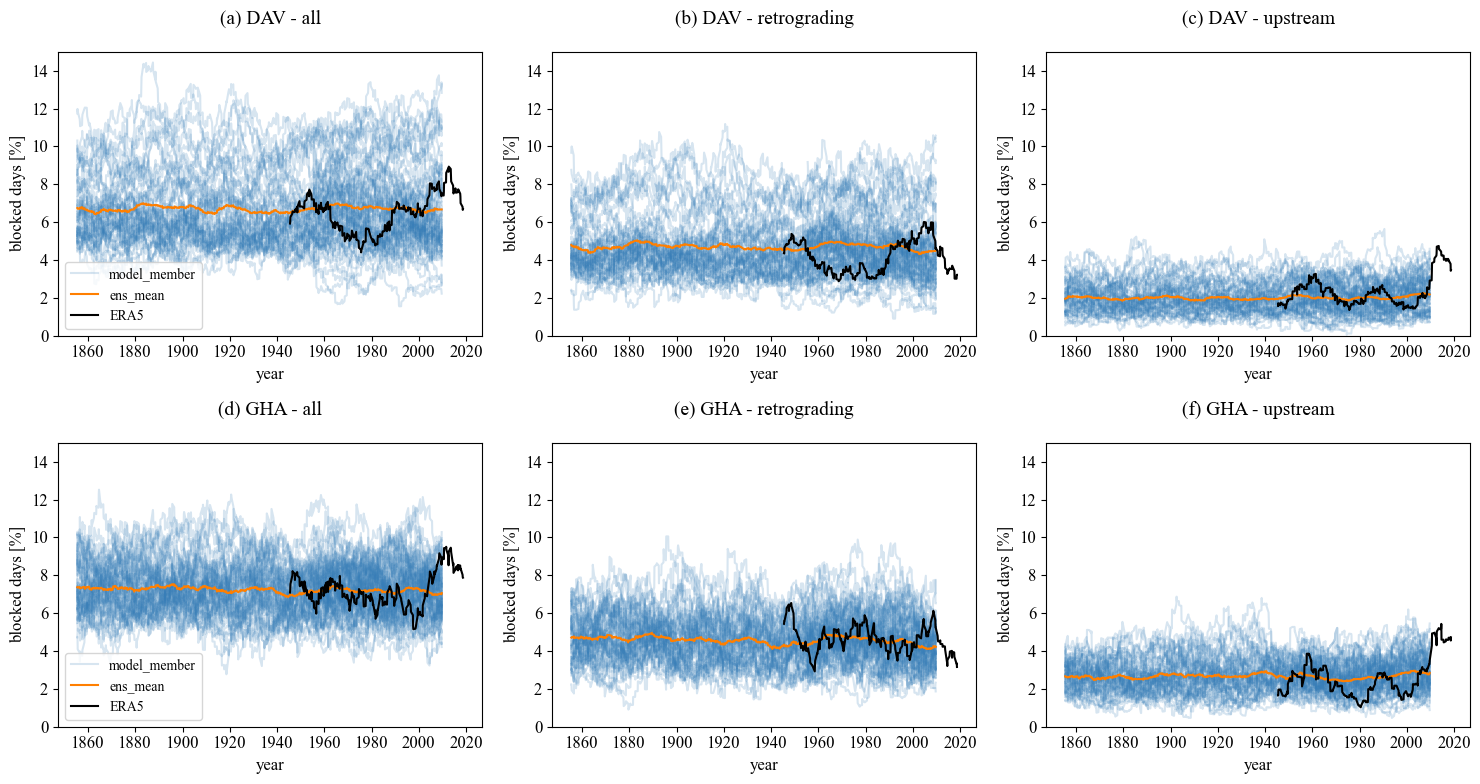

In [15]:
labels = ['all','retrograding (WBI > 0)','upstream (WBI < 0)']

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
axes = axes.flatten()

for ax in axes:
    ax.set_ylim(0,0.15)
    ax.set_yticks([0,0.02,0.04,0.06,0.08,0.10,0.12,0.14])
    ax.set_yticklabels(['0','2','4','6','8','10','12','14'])

title_pad = 20
#plt.suptitle('GHA')
colors = ['#377eb8', '#ff7f00', 'black']

axes[0].set_title('(a) DAV - all',pad=title_pad)
for i,element in enumerate(DAV_DAs_all):
    if i == 0:
        axes[0].plot(element['time'],rollmean(element),color=colors[0],alpha=0.2,label='model_member')
    else:
        axes[0].plot(element['time'],rollmean(element),color=colors[0],alpha=0.2)
axes[0].plot(DAV_average_all['time'],rollmean(DAV_average_all),color = colors[1],label='ens_mean')
axes[0].plot(DAV_ERA5_all['time'],rollmean(DAV_ERA5_all),color = colors[2],label='ERA5')
axes[0].legend(loc = 'lower left',fontsize = 'small')
axes[0].set_ylabel('blocked days [%]')
axes[0].set_xlabel('year')

axes[1].set_title('(b) DAV - retrograding',pad=title_pad)
for element in DAV_DAs_retrograding:
    axes[1].plot(element['time'], rollmean(element),color=colors[0],alpha=0.2)
axes[1].plot(DAV_average_retrograding['time'], rollmean(DAV_average_retrograding),color = colors[1])
axes[1].plot(DAV_ERA5_retrograding['time'], rollmean(DAV_ERA5_retrograding),color = colors[2])
axes[1].set_ylabel('blocked days [%]')
axes[1].set_xlabel('year')

axes[2].set_title('(c) DAV - upstream',pad=title_pad)
for element in DAV_DAs_upstream:
    axes[2].plot(element['time'], rollmean(element),color=colors[0],alpha=0.2)
axes[2].plot(DAV_average_upstream['time'], rollmean(DAV_average_upstream),color = colors[1])
axes[2].plot(DAV_ERA5_upstream['time'], rollmean(DAV_ERA5_upstream),color = colors[2])
axes[2].set_ylabel('blocked days [%]')
axes[2].set_xlabel('year')

axes[3].set_title('(d) GHA - all',pad=title_pad)
for i,element in enumerate(GHA_DAs_all):
    if i == 0:
        axes[3].plot(element['time'],rollmean(element),color=colors[0],alpha=0.2,label='model_member')
    else:
        axes[3].plot(element['time'],rollmean(element),color=colors[0],alpha=0.2)
axes[3].plot(GHA_average_all['time'],rollmean(GHA_average_all),color = colors[1],label='ens_mean')
axes[3].plot(GHA_ERA5_all['time'],rollmean(GHA_ERA5_all),color = colors[2],label='ERA5')
axes[3].legend(loc = 'lower left',fontsize = 'small')
axes[3].set_ylabel('blocked days [%]')
axes[3].set_xlabel('year')

axes[4].set_title('(e) GHA - retrograding',pad=title_pad)
for element in GHA_DAs_retrograding:
    axes[4].plot(element['time'], rollmean(element),color=colors[0],alpha=0.2)
axes[4].plot(GHA_average_retrograding['time'], rollmean(GHA_average_retrograding),color = colors[1])
axes[4].plot(GHA_ERA5_retrograding['time'], rollmean(GHA_ERA5_retrograding),color = colors[2])
axes[4].set_ylabel('blocked days [%]')
axes[4].set_xlabel('year')

axes[5].set_title('(f) GHA - upstream',pad=title_pad)
for element in GHA_DAs_upstream:
    axes[5].plot(element['time'], rollmean(element),color=colors[0],alpha=0.2)
axes[5].plot(GHA_average_upstream['time'], rollmean(GHA_average_upstream),color = colors[1])
axes[5].plot(GHA_ERA5_upstream['time'], rollmean(GHA_ERA5_upstream),color = colors[2])
axes[5].set_ylabel('blocked days [%]')
axes[5].set_xlabel('year')

plt.tight_layout()
plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/CMIP6_hist_analysis/PLOTS/FigureS2.png',dpi=300)

### FREQ VALUES ANALYSIS

In [10]:
n_months = 3*10

#apply to CMIP models -all
#compute distr
GHA_freq_np_arr_all = compute_freq_distribution(GHA_DAs_all)
#compute max ERA5 trend
GHA_freq_ERA5_all,GHA_max_freq_all,GHA_idx_all = compute_ERA5_max_freq(GHA_ERA5_all)

#apply to CMIP models -retrograding
#compute distr
GHA_freq_np_arr_retrograding = compute_freq_distribution(GHA_DAs_retrograding)
#compute max ERA5 trend
GHA_freq_ERA5_retrograding,GHA_max_freq_retrograding,GHA_idx_retrograding = compute_ERA5_max_freq(GHA_ERA5_retrograding)

#apply to CMIP models -upstream
#compute distr
GHA_freq_np_arr_upstream = compute_freq_distribution(GHA_DAs_upstream)
#compute max ERA5 trend
GHA_freq_ERA5_upstream,GHA_max_freq_upstream,GHA_idx_upstream = compute_ERA5_max_freq(GHA_ERA5_upstream)


### SAME BUT FOR DAV

DAV_freq_np_arr_all = compute_freq_distribution(DAV_DAs_all)
DAV_freq_ERA5_all,DAV_max_freq_all,DAV_idx_all = compute_ERA5_max_freq(DAV_ERA5_all)

DAV_freq_np_arr_retrograding = compute_freq_distribution(DAV_DAs_retrograding)
DAV_freq_ERA5_retrograding,DAV_max_freq_retrograding,DAV_idx_retrograding = compute_ERA5_max_freq(DAV_ERA5_retrograding)

DAV_freq_np_arr_upstream = compute_freq_distribution(DAV_DAs_upstream)
DAV_freq_ERA5_upstream,DAV_max_freq_upstream,DAV_idx_upstream = compute_ERA5_max_freq(DAV_ERA5_upstream)

100%|██████████████████████████████████████████████████████████████████████| 70/70 [00:00<00:00, 309.35it/s]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import percentileofscore

# ---- Helper function to make each histogram look nice ---- #

def plot_hist(ax, data, extreme_value, title, color_hist, color_line):
    """
    Plots a histogram with an extreme vertical line, percentile annotation,
    clean styling, and consistent layout.
    """

    bins = np.linspace(0, 1.5, 15)

    # Title
    ax.set_title(title, pad=12)

    # Histogram (nice edges, slight transparency)
    ax.hist(
        data,
        bins=bins,
        color=color_hist,
        edgecolor='black',
        alpha=0.75
    )

    # Vertical line for ERA5 extreme
    ax.axvline(
        x=extreme_value,
        color=color_line,
        linestyle='--',
        linewidth=2
    )

    # Percentile calculation
    pct = percentileofscore(data, extreme_value)

    # Place percentile text in axis coordinates (always visible)
    ax.text(
        0.98, 0.90,                # x, y in axes coords
        f'{pct:.1f}%',
        transform=ax.transAxes,
        ha='right',
        va='top',
    )

    # Axes limits (same as your original)
    ax.set_xlim(0, 1.5)
    ax.set_ylim(0, 25)

    # Labels
    ax.set_xlabel('blocked days [%]')
    ax.set_ylabel('occurrences')

    # Gridlines (clean and light)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

    # Remove top + right spines for a cleaner look
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)



# ---- Your original 6-panel figure ---- #

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
axes = axes.flatten()

# Colors
color_hist = colors[0]
color_line = 'Red'

# --- First row (DAV) --- #

plot_hist(
    axes[0],
    DAV_freq_np_arr_all,
    DAV_max_freq_all,
    '(a) DAV - all',
    color_hist,
    color_line
)

plot_hist(
    axes[1],
    DAV_freq_np_arr_retrograding,
    DAV_freq_ERA5_retrograding[DAV_idx_all],
    '(b) DAV - retrograding',
    color_hist,
    color_line
)

plot_hist(
    axes[2],
    DAV_freq_np_arr_upstream,
    DAV_freq_ERA5_upstream[DAV_idx_all],
    '(c) DAV - upstream',
    color_hist,
    color_line
)

# --- Second row (GHA) --- #

plot_hist(
    axes[3],
    GHA_freq_np_arr_all,
    GHA_max_freq_all,
    '(d) GHA - all',
    color_hist,
    color_line
)

plot_hist(
    axes[4],
    GHA_freq_np_arr_retrograding,
    GHA_freq_ERA5_retrograding[GHA_idx_all],
    '(e) GHA - retrograding',
    color_hist,
    color_line
)

plot_hist(
    axes[5],
    GHA_freq_np_arr_upstream,
    GHA_freq_ERA5_upstream[GHA_idx_all],
    '(f) GHA - upstream',
    color_hist,
    color_line
)


# Tight layout + save
plt.tight_layout()
plt.savefig(
    '/emmy-noether/home/mf671/github/greenland_blocking/CMIP6_hist_analysis/PLOTS/GHA_frequency_distr_analysis.png',
    dpi=300
)